# Santander Dataset

## Load

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb


from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import VotingClassifier

In [49]:
dataset = fetch_openml(data_id=45566, as_frame=True)
df = dataset.frame

df.head()

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199,target
0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,...,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914,False
1,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,...,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518,False
2,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,...,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965,False
3,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,...,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996,False
4,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,...,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104,False


In [50]:
df.describe()

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,7.567236,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,1.235070,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,3.970500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,6.618800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,7.629600,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,8.584425,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,11.150600,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [51]:
df.isna().sum()

var_0      0
var_1      0
var_2      0
var_3      0
var_4      0
          ..
var_196    0
var_197    0
var_198    0
var_199    0
target     0
Length: 201, dtype: int64

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 201 entries, var_0 to target
dtypes: category(1), float64(200)
memory usage: 305.4 MB


In [54]:
print(df["target"].cat.categories)

Index(['False', 'True'], dtype='object')


## Memory

As we have seen the memory usage is too large (305.4 MB), all the variables are of dtype float64, so we will change the dtype of the variables to float32 and check if the memory usage will get lower,
also for the Target, we will change its type to Int64 so it could be better behandled by the machine learning classifiers and to optimize the memory usage.

In [55]:
df = df.pipe(
    lambda df_: df_.astype(
        {col: 'float32' for col in df_.columns if col != 'target'}
    )
).assign(
    target=lambda df_: (df_['target'].cat.codes.astype("int8"))
)

In [88]:
print(df['target'].value_counts())

target
0    179902
1     20098
Name: count, dtype: int64


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 201 entries, var_0 to target
dtypes: float32(200), int8(1)
memory usage: 152.8 MB


We managed to reduce the memory usage to half.

## EDA

Checking null values

In [68]:
df.isnull().sum().sum()

np.int64(0)

Checking duplicated rows

In [80]:
df.duplicated().sum()

np.int64(0)

### Target Distibution

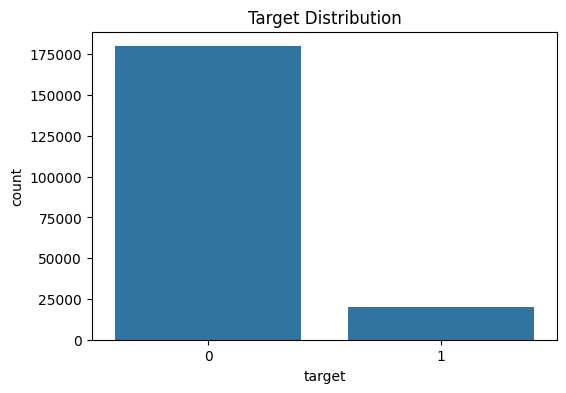

In [86]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target')
plt.title('Target Distribution')
plt.show()

In [87]:
print(df['target'].value_counts(normalize=True))

target
0    0.89951
1    0.10049
Name: proportion, dtype: float64


It's very imbalanced

### Distribution of numerical variables

Random variables

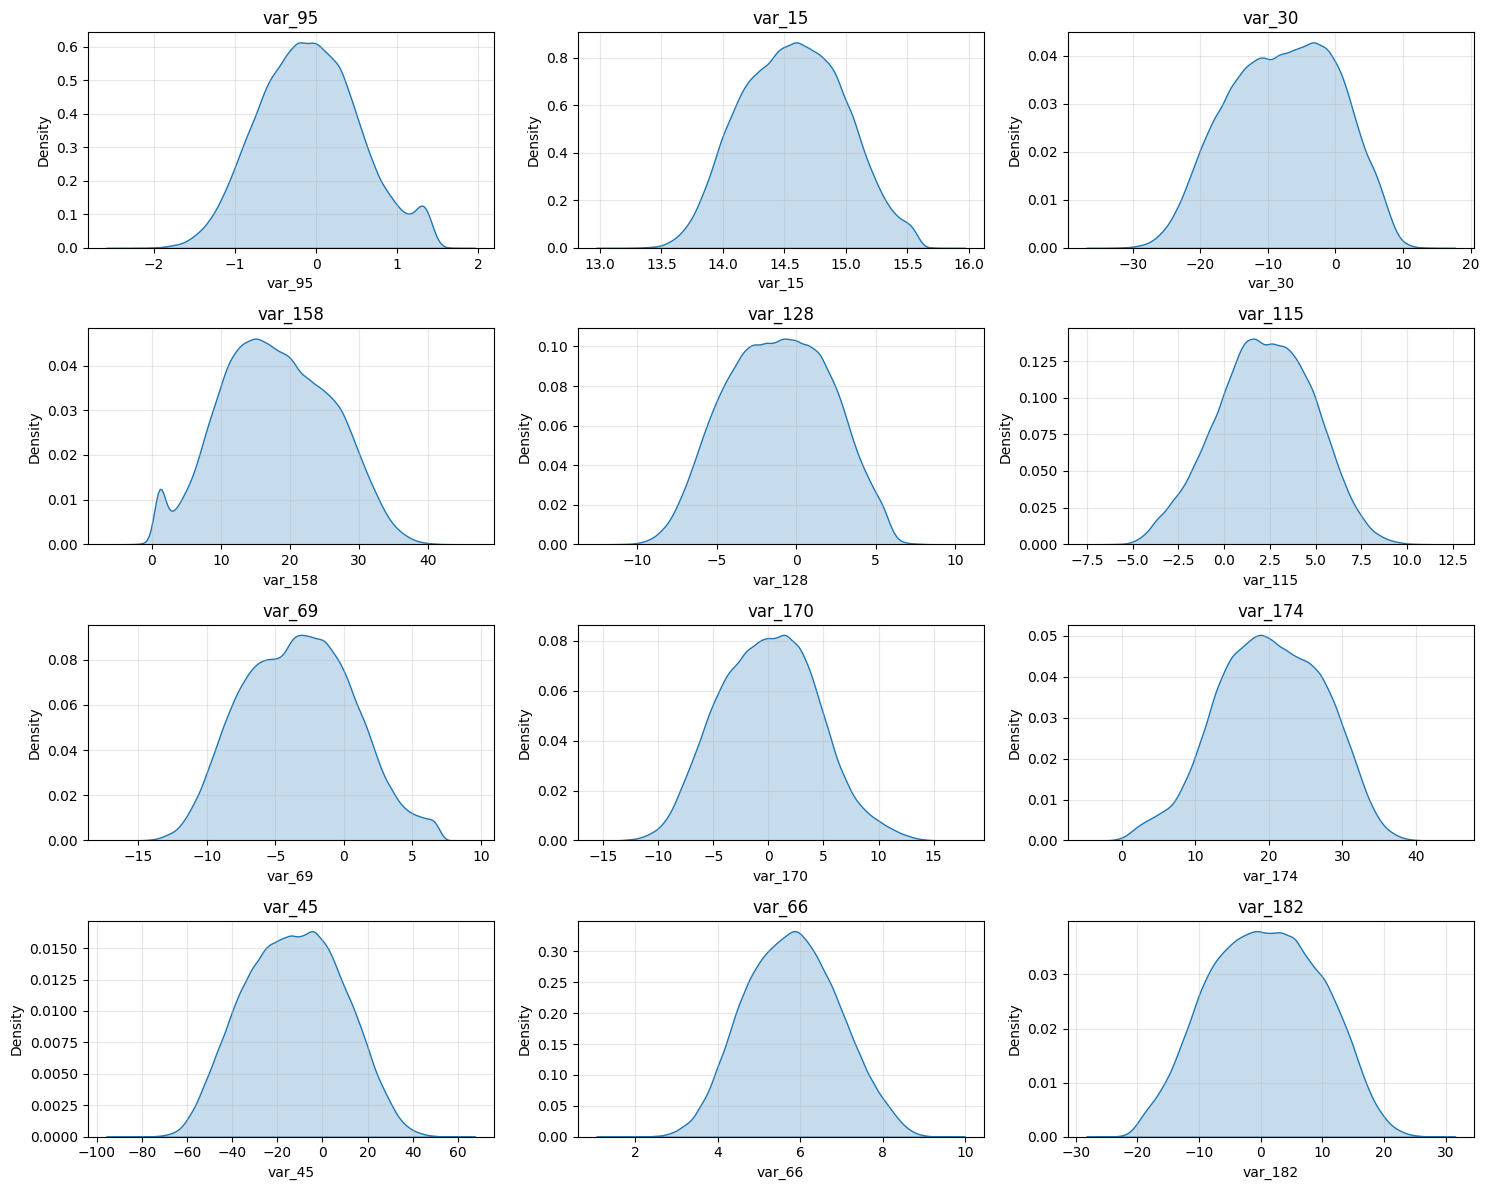

In [94]:
random_cols = df.drop(columns=['target']).sample(n=12, axis=1, random_state=42).columns

fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax, col in zip(axes.flatten(), random_cols):
    sns.kdeplot(data=df, x=col, ax=ax, fill=True)
    ax.set_title(f'{col}')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Variables with the highest variance

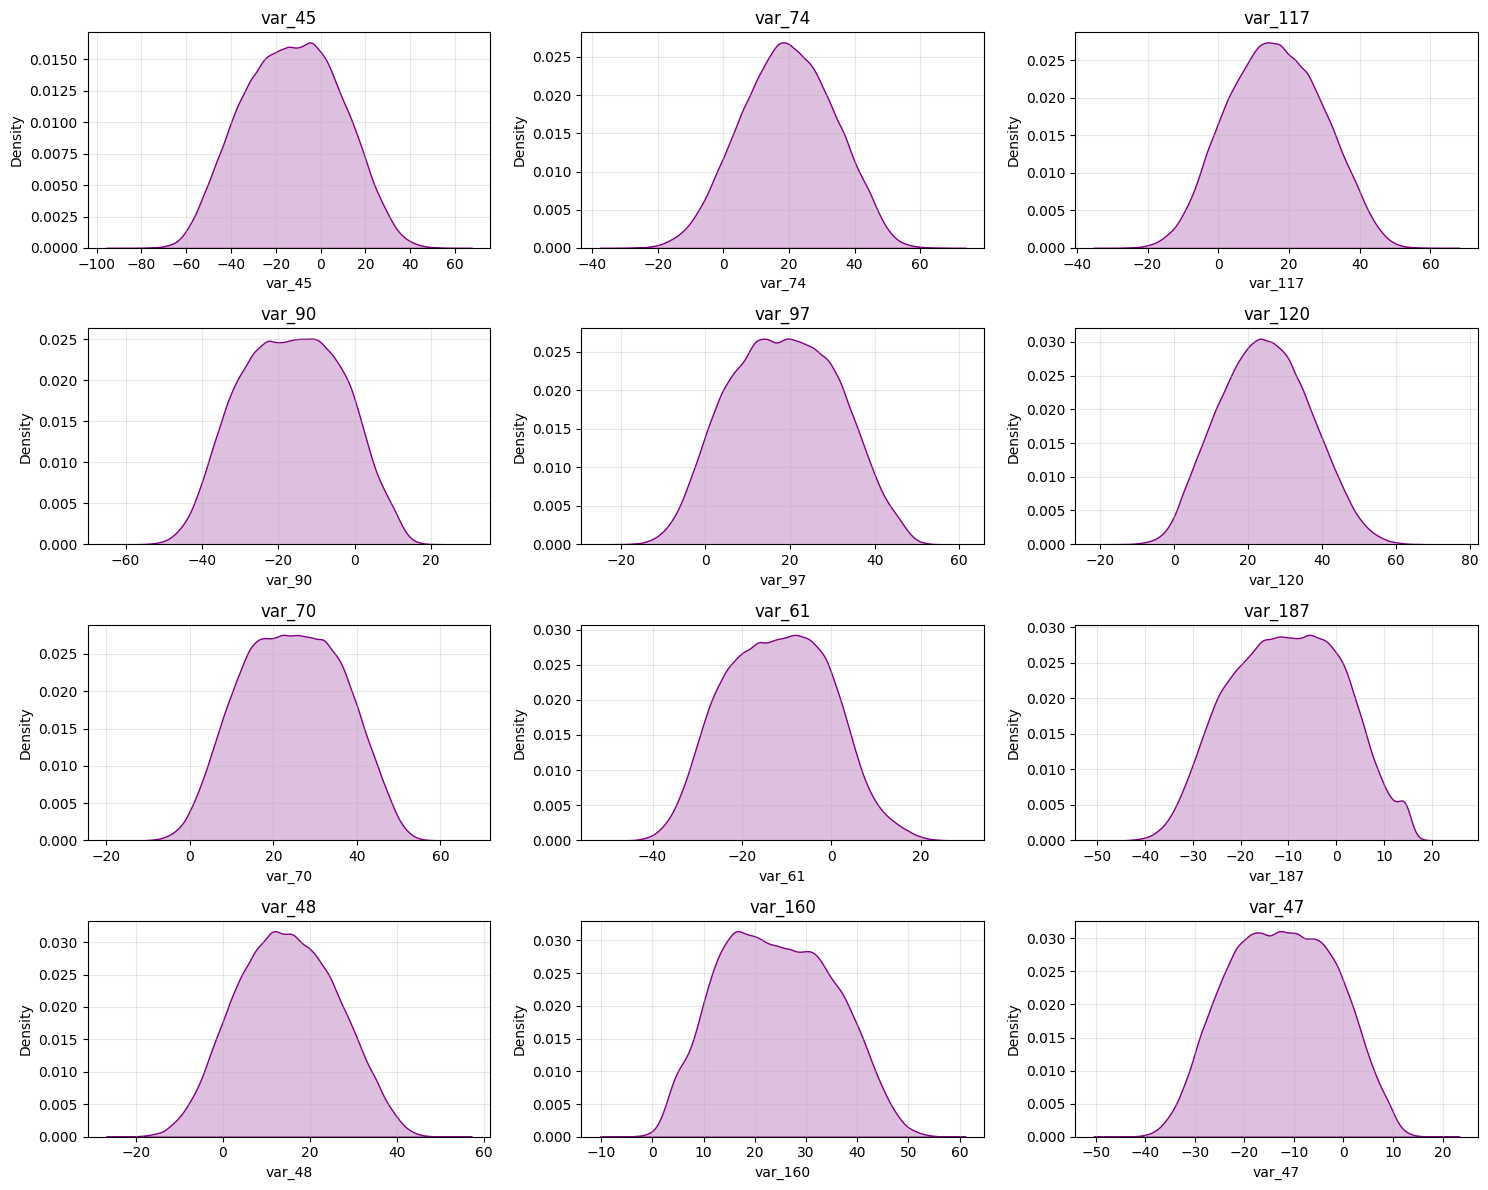

In [93]:
top_12_var_cols = df.drop(columns=['target']).var().nlargest(12).index

fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax, col in zip(axes.flatten(), top_12_var_cols):
    sns.kdeplot(data=df, x=col, ax=ax, fill=True)
    ax.set_title(f'{col}')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Features show symmetric, bell-shaped distributions with near-zero skewness.  
Single-peak curves confirm no hidden sub-clusters per individual feature.

### Checking for Outliers

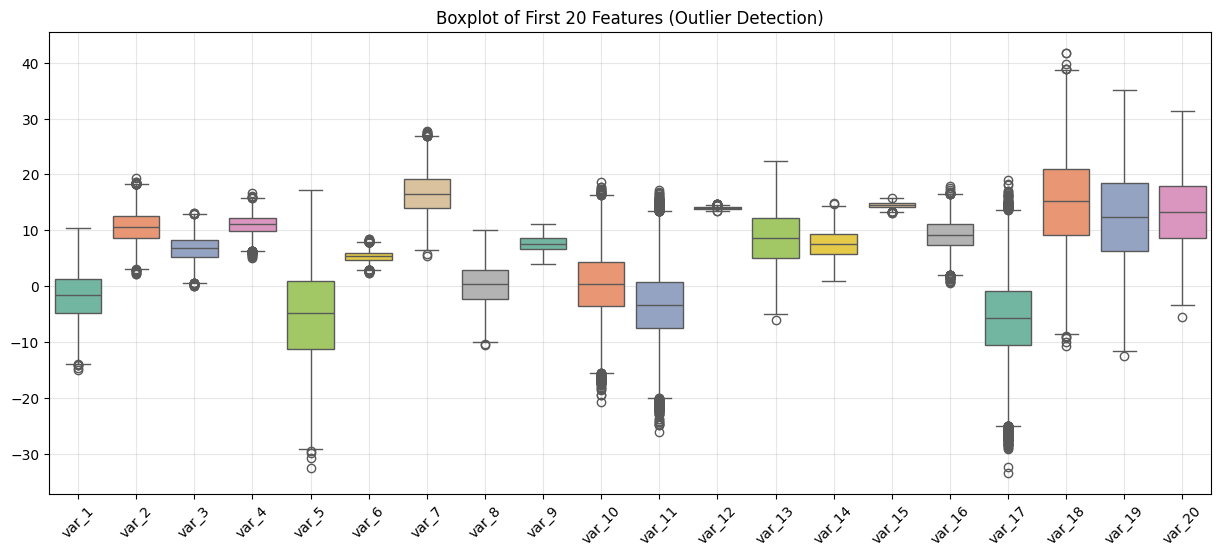

In [96]:
plt.figure(figsize=(15, 6))
sns.boxplot(data=df.iloc[:, 1:21], palette='Set2')
plt.xticks(rotation=45)
plt.title('Boxplot of First 20 Features (Outlier Detection)')
plt.grid(alpha=0.3)
plt.show()

There are some outliers, but they are natural tail values of high-volume Gaussian distributions, not corrupt data points.

### Correlation

Multicollinearity

In [99]:
(
    df.corr()
      .abs()
      .pipe(lambda corr: pd.DataFrame(np.where(np.triu(np.ones(corr.shape), k=1).astype(bool), corr, np.nan), 
                                      index=corr.index, columns=corr.columns))
      .stack()
      .max()
)

np.float64(0.0809173322514417)

The correlation between the most two correlated features is '0.08' which means there isn't any correlation between any two features.

Correlation to the target

In [102]:
top_target_corr=(
    df.corr()
      .abs()
      ['target']
      .drop('target')
      .sort_values(ascending=False)
      .head(10)
)

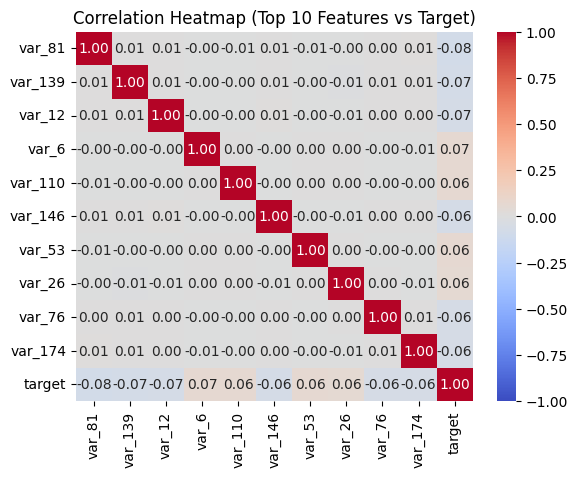

In [103]:
top_features = top_target_corr.index.tolist() + ['target']

(
    df[top_features]
      .corr()
      .pipe(lambda corr_df: sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1))
)
plt.title('Correlation Heatmap (Top 10 Features vs Target)')
plt.show()

Also there isn't any individual correlation to the target

## Machine learning

### Logistic Regression

In [107]:
lr_auc = (
    lambda X_tr, X_va, y_tr, y_va: roc_auc_score(
        y_va,
        LogisticRegression(max_iter=1000, random_state=42)
        .fit(X_tr, y_tr)
        .predict_proba(X_va)[:, 1]
    )
)(*train_test_split(df.drop(columns=['target']), df['target'], test_size=0.20, stratify=df['target'], random_state=42))

c:\Users\Lenovo\Documents\advanced-data-analytics\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [109]:
lr_auc * 100

85.79388217334673

In [137]:
lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

In [112]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [115]:
cv_scores = cross_val_score(
    lr_pipeline, 
    df.drop(columns=['target']), 
    df['target'], 
    cv=skf, 
    scoring='roc_auc', 
    n_jobs=-1
)

cv_scores.mean() * 100

np.float64(85.94905649888854)

The best score we got in this model is 85.94%

### Gaussian Naive Bayes

In [117]:
gnb_scores = cross_val_score(
    GaussianNB(),
    df.drop(columns=['target']),
    df['target'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)

In [119]:
gnb_scores.mean() * 100

np.float64(88.05165914966989)

In [ ]:
gnb_quantile_auc = cross_val_score(
    make_pipeline(
        QuantileTransformer(output_distribution='normal', random_state=42),
        GaussianNB()
    ),
    df.drop(columns=['target']),
    df['target'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
).mean()

In [182]:
gnb_quantile_auc * 100

np.float64(88.79254031410213)

We have a score of 88.79% which is significantly an improvement from the Logistic regression.

### XGBoost

In [128]:
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    tree_method='hist',
    random_state=42,
    eval_metric='auc',
    n_jobs=-1
)

In [130]:
xgb_cv_scores = cross_val_score(
    xgb_model,
    df.drop(columns=['target']),
    df['target'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)

In [132]:
xgb_cv_scores.mean()

np.float64(0.8466621247708715)

Baseline score is 84.66%.  
We can do some tuning

In [136]:
pipe = make_pipeline(
    xgb.XGBClassifier(
        tree_method='hist',
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    )
)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None


In [138]:
param_distributions = {
    'xgbclassifier__max_depth': [2, 3, 4],
    'xgbclassifier__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'xgbclassifier__n_estimators': [200, 300, 400],
    'xgbclassifier__colsample_bytree': [0.4, 0.6, 0.8],
    'xgbclassifier__subsample': [0.7, 0.8, 0.9],
    'xgbclassifier__min_child_weight': [1, 5, 10]
}

In [141]:
xgb_random = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=10,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [142]:
xgb_random.fit(df.drop(columns=['target']), df['target'])

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgbclassifier__colsample_bytree': [0.4, 0.6, ...], 'xgbclassifier__learning_rate': [0.03, 0.05, ...], 'xgbclassifier__max_depth': [2, 3, ...], 'xgbclassifier__min_child_weight': [1, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide

In [144]:
print(f" Best Params: {xgb_random.best_params_}")
print(f" Best Tuned XGBoost ROC-AUC: {xgb_random.best_score_:.5f}")

 Best Params: {'xgbclassifier__subsample': 0.8, 'xgbclassifier__n_estimators': 400, 'xgbclassifier__min_child_weight': 10, 'xgbclassifier__max_depth': 4, 'xgbclassifier__learning_rate': 0.08, 'xgbclassifier__colsample_bytree': 0.8}
 Best Tuned XGBoost ROC-AUC: 0.88360


We got a score of 88.36%, it has improved from the base model.  
Now lets look at the most important features.

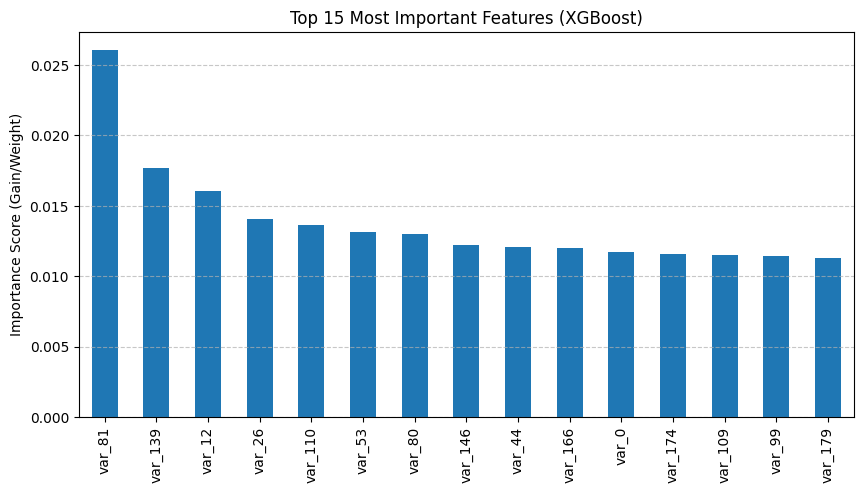

In [145]:
best_xgb = xgb_random.best_estimator_.named_steps['xgbclassifier']

feature_importances = pd.Series(
    best_xgb.feature_importances_, 
    index=df.drop(columns=['target']).columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feature_importances.head(15).plot(kind='bar', color='#1f77b4')
plt.title("Top 15 Most Important Features (XGBoost)")
plt.ylabel("Importance Score (Gain/Weight)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

var_81 is really important for the decision, but it's not enough as we can see that the difference between the other features is really small.

### LightGBM

In [150]:
lgb_base_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
lgb_base_model

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [148]:
lgb_cv_scores = cross_val_score(
    lgb_base_model,
    df.drop(columns=['target']),
    df['target'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)

In [151]:
lgb_cv_scores.mean()

np.float64(0.865207233895716)

86.52% score for the base model is good but not enough.  
Lets tune

In [153]:
lgb_pipe = make_pipeline(
    lgb.LGBMClassifier(
        objective='binary',
        boosting_type='gbdt',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
)

lgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('lgbmclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,'binary'


In [152]:
param_distributions = {
    'lgbmclassifier__num_leaves': [15, 31, 63],
    'lgbmclassifier__learning_rate': [0.03, 0.05, 0.08],
    'lgbmclassifier__n_estimators': [200, 300, 400],
    'lgbmclassifier__colsample_bytree': [0.4, 0.6, 0.8],
    'lgbmclassifier__subsample': [0.7, 0.8, 0.9],
    'lgbmclassifier__min_child_samples': [20, 50, 100]
}

In [154]:
lgb_random = RandomizedSearchCV(
    estimator=lgb_pipe,
    param_distributions=param_distributions,
    n_iter=10,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [155]:
lgb_random.fit(df.drop(columns=['target']), df['target'])

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...verbose=-1))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'lgbmclassifier__colsample_bytree': [0.4, 0.6, ...], 'lgbmclassifier__learning_rate': [0.03, 0.05, ...], 'lgbmclassifier__min_child_samples': [20, 50, ...], 'lgbmclassifier__n_estimators': [200, 300, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref

In [157]:
print(f" Best Params: {lgb_random.best_params_}")
print(f" Best Tuned LightGBM ROC-AUC: {lgb_random.best_score_:.5f}")

 Best Params: {'lgbmclassifier__subsample': 0.8, 'lgbmclassifier__num_leaves': 63, 'lgbmclassifier__n_estimators': 400, 'lgbmclassifier__min_child_samples': 50, 'lgbmclassifier__learning_rate': 0.05, 'lgbmclassifier__colsample_bytree': 0.4}
 Best Tuned LightGBM ROC-AUC: 0.88809


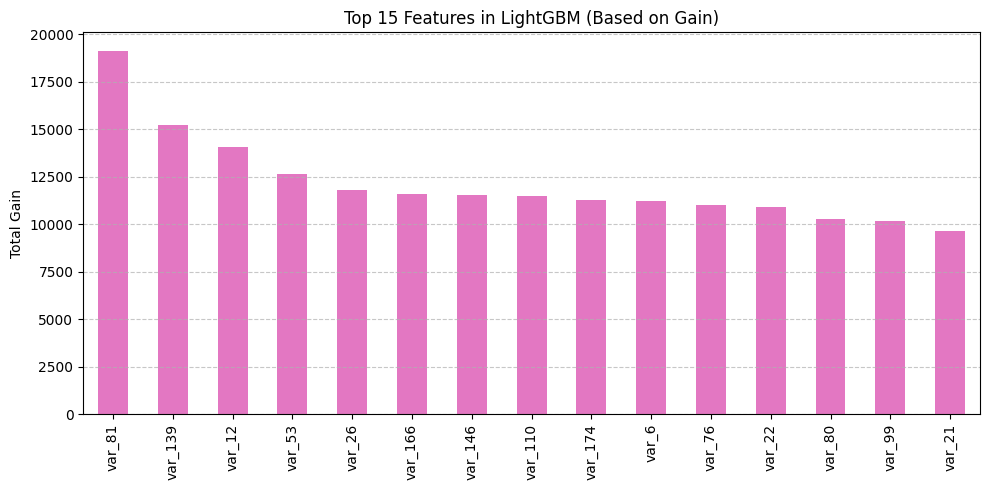

In [176]:
gain_importances = best_lgb.booster_.feature_importance(importance_type='gain')
lgb_gain_series = pd.Series(gain_importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
lgb_gain_series.head(15).plot(kind='bar', color='#e377c2')
plt.title("Top 15 Features in LightGBM (Based on Gain)")
plt.ylabel("Total Gain")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Ensembling

In [163]:
pipe_nb = make_pipeline(
    QuantileTransformer(output_distribution='normal', random_state=42),
    GaussianNB()
)
pipe_nb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('quantiletransformer', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"n_quantiles n_quantiles: int, default=1000 or n_samplesNumber of quantiles to be computed. It corresponds to the numberof landmarks used to discretize the cumulative distribution function.If n_quantiles is larger than the number of samples, n_quantiles is setto the number of samples as a larger number of quantiles does not givea better approximation of the cumulative distribution functionestimator.",1000
,"output_distribution output_distribution: {'uniform', 'normal'}, default='uniform'Marginal distribution for the transformed data. The choices are'uniform' (default) or 'normal'.",'normal'
,"ignore_implicit_zeros ignore_implicit_zeros: bool, default=FalseOnly applies to sparse matrices. If True, the sparse entries of thematrix are discarded to compute the quantile statistics. If False,these entries are treated as zeros.",False
,"subsample subsample: int or None, default=10_000Maximum number of samples used to estimate the quantiles forcomputational efficiency. Note that the subsampling procedure maydiffer for value-identical sparse and dense matrices.Disable subsampling by setting `subsample=None`... versionadded:: 1.5 The option `None` to disable subsampling was added.",10000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for subsampling and smoothingnoise.Please see ``subsample`` for more details.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42
,"copy copy: bool, default=TrueSet to False to perform inplace transformation and avoid a copy (if theinput is already a numpy array).",True
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [170]:
pipe_xgb = make_pipeline(
    xgb.XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.08,
        subsample=0.8,
        min_child_weight=10,
        colsample_bytree=0.8,
        tree_method='hist',
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
)


pipe_xgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8


In [172]:
pipe_lgb = make_pipeline(
    lgb.LGBMClassifier(
        n_estimators=400,
        num_leaves=63,
        learning_rate=0.05,
        subsample=0.8,
        min_child_samples=50,
        colsample_bytree=0.4,
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )
)
pipe_lgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('lgbmclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,boosting_type,'gbdt'
,num_leaves,63
,max_depth,-1
,learning_rate,0.05
,n_estimators,400
,subsample_for_bin,200000
,objective,None


In [174]:
ensemble_model = VotingClassifier(
    estimators=[
        ('nb', pipe_nb),
        ('xgb', pipe_xgb),
        ('lgb', pipe_lgb)
    ],
    voting='soft',
    weights=[0.35, 0.25, 0.40],
    n_jobs=-1
)

In [175]:
ensemble_scores = cross_val_score(
    ensemble_model,
    df.drop(columns=['target']),
    df['target'],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)

In [181]:
print(f" Final Ensemble ROC-AUC: {ensemble_scores.mean():.5f} (+/- {ensemble_scores.std():.5f})")

 Final Ensemble ROC-AUC: 0.89461 (+/- 0.00287)


After ensembling our best models, we got a ROC-AUC score of 89.64%

In [189]:
def print_ascii_bar_chart():
    # 1. إدخال بيانات النماذج والنتائج
    results = {
        "Logistic Regression (Baseline)": 0.8595,
        "Gaussian Naive Bayes (Raw)": 0.8805,
        "XGBoost (Tuned)": 0.8836,
        "LightGBM (Tuned)": 0.8881,
        "QuantileTransformer + GNB": 0.8879,
        "Final Heterogeneous Ensemble": 0.8946
    }
    
    # 2. إعدادات الرسم البياني
    min_val = 0.80
    max_val = 0.90
    bar_length = 28 # عرض الشريط بالمسافات
    block_char = '█'
    
    max_name_len = max(len(name) for name in results.keys())
    best_score = max(results.values())
    
    print("[Progression des ROC-AUC Scores über die Projektphasen]\n")
    
    # 3. توليد وطباعة الأعمدة
    for name, score in results.items():
        # حساب نسبة التعبئة بناءً على النطاق 0.80 إلى 0.90
        fill_ratio = (score - min_val) / (max_val - min_val)
        fill_ratio = max(0, min(1, fill_ratio)) # لضمان عدم تجاوز الحدود
        
        num_blocks = int(round(fill_ratio * bar_length))
        num_spaces = bar_length - num_blocks
        
        bar = (block_char * num_blocks) + (' ' * num_spaces)
        
        annotation = "  <-- Bester Score" if score == best_score else ""
        
        # طباعة السطر منسقاً
        print(f"{name:<{max_name_len}} : |{bar}| {score:.4f}{annotation}")
    
    # 4. طباعة المحور السفلي
    axis_line = "+" + ("-" * bar_length) + "+"
    print(f"{'':<{max_name_len}}   {axis_line}")
    print(f"{'':<{max_name_len}}   0.80{'':<{bar_length - 4}}0.90")

# تشغيل الدالة
print_ascii_bar_chart()

[Progression des ROC-AUC Scores über die Projektphasen]

Logistic Regression (Baseline) : |█████████████████           | 0.8595
Gaussian Naive Bayes (Raw)     : |███████████████████████     | 0.8805
XGBoost (Tuned)                : |███████████████████████     | 0.8836
LightGBM (Tuned)               : |█████████████████████████   | 0.8881
QuantileTransformer + GNB      : |█████████████████████████   | 0.8879
Final Heterogeneous Ensemble   : |██████████████████████████  | 0.8946  <-- Bester Score
                                 +----------------------------+
                                 0.80                        0.90
